# Исследование помехоустойчивости кодов Хэмминга и свёрточных кодов при передаче данных по каналу с шумом

**Сравнение трёх режимов передачи в канале AWGN с модуляцией BPSK и жёстким решением:**

| № | Режим | Код | Скорость $R$ | Декодирование |
|---|-------|-----|--------------|----------------|
| 1 | без кодирования | — | 1 | — |
| 2 | код Хэмминга (7,4) | $n=7,\ k=4,\ d_{min}=3$ | $4/7$ | синдромное, исправление 1 ошибки |
| 3 | свёрточный код | $R=1/2,\ K=3,\ (7,5)_8$ | $L/(2(L+2))$ | Витерби, жёсткие решения |

**Авторство материалов**

* архитектура, код, тесты, эксперимент, визуализация — Агент №1 (Research Software Engineer);
* математическая модель, методология, параметры исследования, правила расчёта BER, интерпретация — Агент №2.

Все числовые результаты в этом notebook получены **запуском** программного кода проекта
и сохранены в `results/data/*.csv`. Ни одно число не вписано вручную.

## 1. Цель и задачи

**Цель:** количественно оценить, насколько помехоустойчивое кодирование снижает вероятность
ошибки на бит (BER) по сравнению с передачей без кодирования в канале AWGN с BPSK и жёстким
решением.

**Задачи:**

1. реализовать код Хэмминга (7,4) и свёрточный код $R=1/2$, $K=3$, $(7,5)_8$ с декодером Витерби;
2. проверить кодеры и декодеры на контрольных векторах и полным перебором;
3. смоделировать канал BPSK + AWGN с нормировкой энергии на информационный бит;
4. провести BER-эксперимент для $E_b/N_0 = 0\ldots10$ дБ с шагом 1 дБ;
5. сопоставить результаты с теоретическими кривыми;
6. вычислить энергетический выигрыш кодированных схем;
7. зафиксировать воспроизводимость (seed, версии, параметры).

**Единицы измерения.** $E_b/N_0$ — отношение энергии, приходящейся на **один информационный бит
до кодирования**, к спектральной плотности шума. Это единственное определение, при котором
сравнение схем с разными скоростями корректно. BER считается только по информационным битам:
$\mathrm{BER} = N_{errors} / N_{info}$.

## 2. Используемые библиотеки и окружение

Используются только `numpy`, `matplotlib` и стандартная библиотека Python
(`math.erfc` для Q-функции). Пакет `scipy` не применяется; кодеры и декодеры
реализованы вручную в пакете `src`.

Пакет `src`:

| Модуль | Содержание |
|--------|-----------|
| `hamming` | код Хэмминга (7,4): кодирование, синдром, коррекция, декодирование |
| `convolutional` | свёрточный кодер $(7,5)_8$, таблица переходов, zero-tail |
| `viterbi` | декодер Витерби для жёстких решений (пакетный) |
| `channel` | BPSK, AWGN, $\sigma^2 = 1/(2R_{eff}\gamma_b)$, жёсткий демодулятор |
| `metrics` | BER, точные интервалы, теория BPSK и Хэмминга, энергетический выигрыш |
| `simulation` | фиксированный план эксперимента, счётчики, CSV |
| `plotting` | графики только из сохранённых CSV |

In [1]:
import os, sys, subprocess, platform
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

# корень проекта (notebook лежит в notebooks/)
ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if os.path.basename(os.getcwd()) != "notebooks":
    ROOT = os.path.abspath(os.getcwd())
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

from src import hamming, convolutional as conv, viterbi, channel, metrics, simulation, plotting

DATA = os.path.join(ROOT, "results", "data")
FIG = os.path.join(ROOT, "results", "figures")

print("Python     :", platform.python_version())
print("NumPy      :", np.__version__)
print("Matplotlib :", matplotlib.__version__)
print("корень     :", ROOT)

Python     : 3.13.16
NumPy      : 2.3.5
Matplotlib : 3.10.9
корень     : /home/user/coding_noise_research


## 3. Параметры эксперимента

Параметры зафиксированы **до** запуска и не подбирались по результатам.

In [2]:
plan = simulation.Plan()
print("seed:", plan.seed)
print("Eb/N0, дБ:", list(plan.ebno_db))
print()
print(f"{'схема':<16}{'N_info':>12}{'единиц M':>14}{'R_nominal':>11}{'R_eff':>10}")
r_eff = plan.r_eff
print(f"{'без кодирования':<16}{plan.n_info_uncoded:>12,}{plan.n_info_uncoded:>14,}"
      f"{1.0:>11.3f}{r_eff['uncoded']:>10.5f}")
print(f"{'Хэмминг (7,4)':<16}{plan.n_info_hamming:>12,}{plan.n_info_hamming//4:>14,}"
      f"{hamming.RATE:>11.3f}{r_eff['hamming']:>10.5f}")
print(f"{'свёрточный':<16}{plan.n_info_convolutional:>12,}"
      f"{plan.n_info_convolutional//plan.packet_length:>14,}{0.5:>11.3f}"
      f"{r_eff['convolutional']:>10.5f}")
print()
print("параметры кодов:")
print("  Хэмминг: n=7, k=4, d_min=3, t=1, проверочные позиции 1,2,4; информационные 3,5,6,7")
print(f"  свёрточный: K=3, g1=7_8, g2=5_8, состояний {conv.N_STATES}, "
      f"хвост {conv.TAIL} бита, d_free={conv.D_FREE}")
print(f"  надбавка за хвост: {conv.energy_penalty_db(plan.packet_length):.6f} дБ")

seed: 20261024
Eb/N0, дБ: [0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0]

схема                 N_info      единиц M  R_nominal     R_eff
без кодирования    2,000,000     2,000,000      1.000   1.00000
Хэмминг (7,4)      2,000,000       500,000      0.571   0.57143
свёрточный         1,000,000           100      0.500   0.49990

параметры кодов:
  Хэмминг: n=7, k=4, d_min=3, t=1, проверочные позиции 1,2,4; информационные 3,5,6,7
  свёрточный: K=3, g1=7_8, g2=5_8, состояний 4, хвост 2 бита, d_free=5
  надбавка за хвост: 0.000869 дБ


## 4. Теоретические сведения

### 4.1. Канал и жёсткое решение

BPSK: $x = 1-2b$, то есть $0 \to +1$, $1 \to -1$, энергия символа $E_s = 1$.
Канал: $y = x + n$, где $n \sim \mathcal{N}(0, \sigma^2)$ независимы.

Нормировка энергии на информационный бит:

$$
\sigma^2 = \frac{1}{2\,R_{eff}\,\gamma_b}, \qquad \gamma_b = 10^{E_b/N_0\,[\text{дБ}]/10},
$$

где $R_{eff}$ — **фактическая** скорость кода с учётом хвостовых битов. Жёсткое решение:
$\hat b = 1$ при $y<0$, иначе $0$. Вероятность ошибки передаваемого бита
$p = Q\!\left(\sqrt{2R_{eff}\gamma_b}\right)$.

### 4.2. Без кодирования

$$
P_b = Q\!\left(\sqrt{2\gamma_b}\right) = \tfrac12\,\mathrm{erfc}\!\left(\sqrt{\gamma_b}\right).
$$

### 4.3. Код Хэмминга (7,4)

Слово $(p_1,p_2,d_1,p_4,d_2,d_3,d_4)$, проверки $c_1\!\oplus\!c_3\!\oplus\!c_5\!\oplus\!c_7=0$ и т. д.
Синдром $s = rH^{T}$, номер позиции $j = s_1 + 2s_2 + 4s_4$. Код совершенный:
$2^k(1+n) = 2^n$, поэтому декодер не имеет исхода «отказ».

**Точная BER при жёстких решениях.** Декодер линеен и транслиционно инвариантен, поэтому можно
передавать нулевое слово и перебирать все $2^7=128$ шаблонов ошибок $e$ с весом $w$ и числом
ошибочных информационных битов $z(e)$:

$$
P_b = \frac14 \sum_{e\in\{0,1\}^7} z(e)\,p^{w}(1-p)^{7-w}
    = 9p^2 - 26p^3 + 30p^4 - 12p^5 .
$$

(В коде используется эквивалентная форма суммы неотрицательных слагаемых.)

### 4.4. Свёрточный код $(7,5)_8$ и Витерби

Состояние $S_t=(a,b)=(u_{t-1},u_{t-2})$, индекс $s=2a+b$; выходы
$v_1 = u\oplus a\oplus b$, $v_2 = u\oplus b$; $S_{t+1}=(u,a)$.

**Свободное расстояние $d_{free}=5$** — по доказательству на четырёхсостоятельной
диаграмме: путь по входу 100 идёт $00\to10\to01\to00$ с выходом $11|10|11$; первое
ребро и ребро возврата имеют вес 2, среднее ребро — вес 1, поэтому меньший суммарный
вес невозможен (обход через состояние 11 минимума не уменьшает). Перебор информационных
слов до длины 12 в коде — **вычислительное подтверждение** на конечном диапазоне,
а не самостоятельное доказательство глобального минимума; в научном тексте используется
доказательство по диаграмме.

Завершение нулевое: к $L$ битам добавляются $K-1=2$ нуля, $T=L+2$ шагов,
$N_{tx}=2(L+2)$, $R_{eff}=L/[2(L+2)]$. Декодер Витерби для жёстких решений минимизирует
расстояние Хэмминга по пути — это ML по кодовому пути (не побитовый MAP).
При равенстве метрик выбирается ребро с меньшим номером предыдущего состояния; правило
одинаково во всём исследовании.

### 4.5. Как учитывается зависимость ошибок

После декодирования ошибки внутри единицы декодирования зависимы. Независимая единица:
бит (без кодирования), блок из 4 бит (Хэмминг), завершённый пакет (Витерби).
Если $I_j=\mathbf{1}[Z_j>0]$, $K=\sum_j I_j \sim \mathrm{Bin}(M,q)$ и
$I_j \le Z_j \le \ell I_j$, то $q/\ell \le P_b \le q$; следовательно
$[q_{low}/\ell,\ q_{high}]$ — консервативный 95 %-й интервал для BER
(Клоппер—Пирсон для $K$ из $M$). При $E=0$ используется односторонняя граница
$q_{upper} = 1-0.05^{1/M}$ (не $3/N_{info}$).

## 5. Модель системы связи

Последовательность обработки: источник случайных битов → кодер → BPSK → AWGN →
жёсткий демодулятор → декодер → подсчёт битовых ошибок по информационным битам.

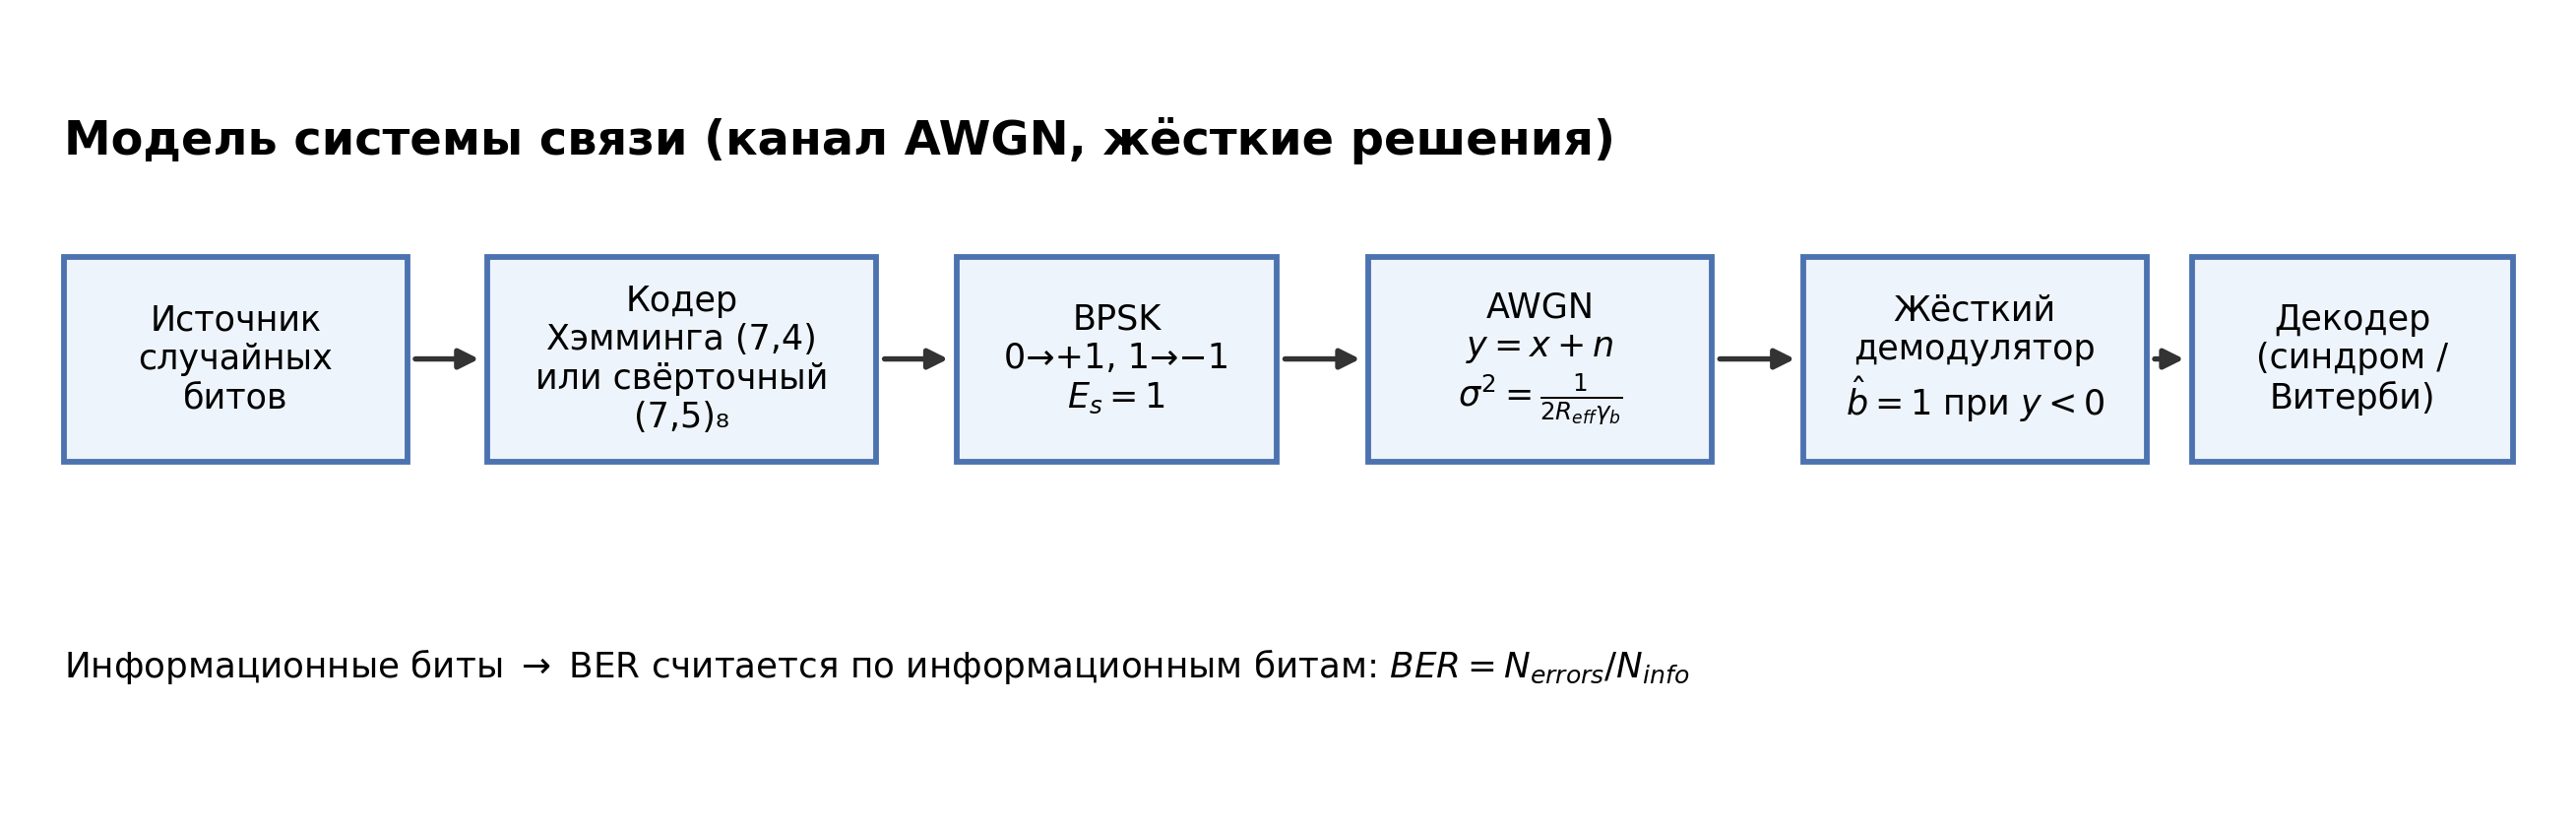

In [3]:
from IPython.display import Image, display
display(Image(filename=os.path.join(FIG, "channel_scheme.png"), width=1000))

## 6. Код Хэмминга (7,4): проверка и иллюстрация

Матрицы и свойства кода проверяются в разделе тестов; здесь — демонстрация
кодирования, синдрома и исправления ошибки.

In [4]:
print("Порождающая матрица G (4x7):"); print(hamming.G)
print("\nПроверочная матрица H (3x7):"); print(hamming.H)
print("\nG·H^T mod 2 = 0:", bool(np.all((hamming.G.astype(int) @ hamming.H.T.astype(int)) % 2 == 0)))
print("минимальное расстояние d_min =", hamming.min_distance())

info = np.array([1, 0, 1, 1], dtype=np.uint8)
code = hamming.encode(info)
print("\nинформация:", "".join(map(str, info)), "-> кодовое слово:", "".join(map(str, code)))

print("\nпозиция | синдром (s1,s2,s4) | j | декодировано")
for pos in [None] + list(range(7)):
    rx = code.copy()
    if pos is not None:
        rx[pos] ^= 1
    d = hamming.decode_with_diagnostics(rx)
    j = int(d["error_position"][0])
    print(f"{'—' if pos is None else pos + 1:>7} | "
          f"({int(d['syndrome'][0,0])},{int(d['syndrome'][0,1])},{int(d['syndrome'][0,2])})"
          f"            | {j} | {''.join(map(str, d['bits']))}")

Порождающая матрица G (4x7):
[[1 1 1 0 0 0 0]
 [1 0 0 1 1 0 0]
 [0 1 0 1 0 1 0]
 [1 1 0 1 0 0 1]]

Проверочная матрица H (3x7):
[[1 0 1 0 1 0 1]
 [0 1 1 0 0 1 1]
 [0 0 0 1 1 1 1]]

G·H^T mod 2 = 0: True
минимальное расстояние d_min = 3

информация: 1011 -> кодовое слово: 0110011

позиция | синдром (s1,s2,s4) | j | декодировано
      — | (0,0,0)            | 0 | 1011
      1 | (1,0,0)            | 1 | 1011
      2 | (0,1,0)            | 2 | 1011
      3 | (1,1,0)            | 3 | 1011
      4 | (0,0,1)            | 4 | 1011
      5 | (1,0,1)            | 5 | 1011
      6 | (0,1,1)            | 6 | 1011
      7 | (1,1,1)            | 7 | 1011


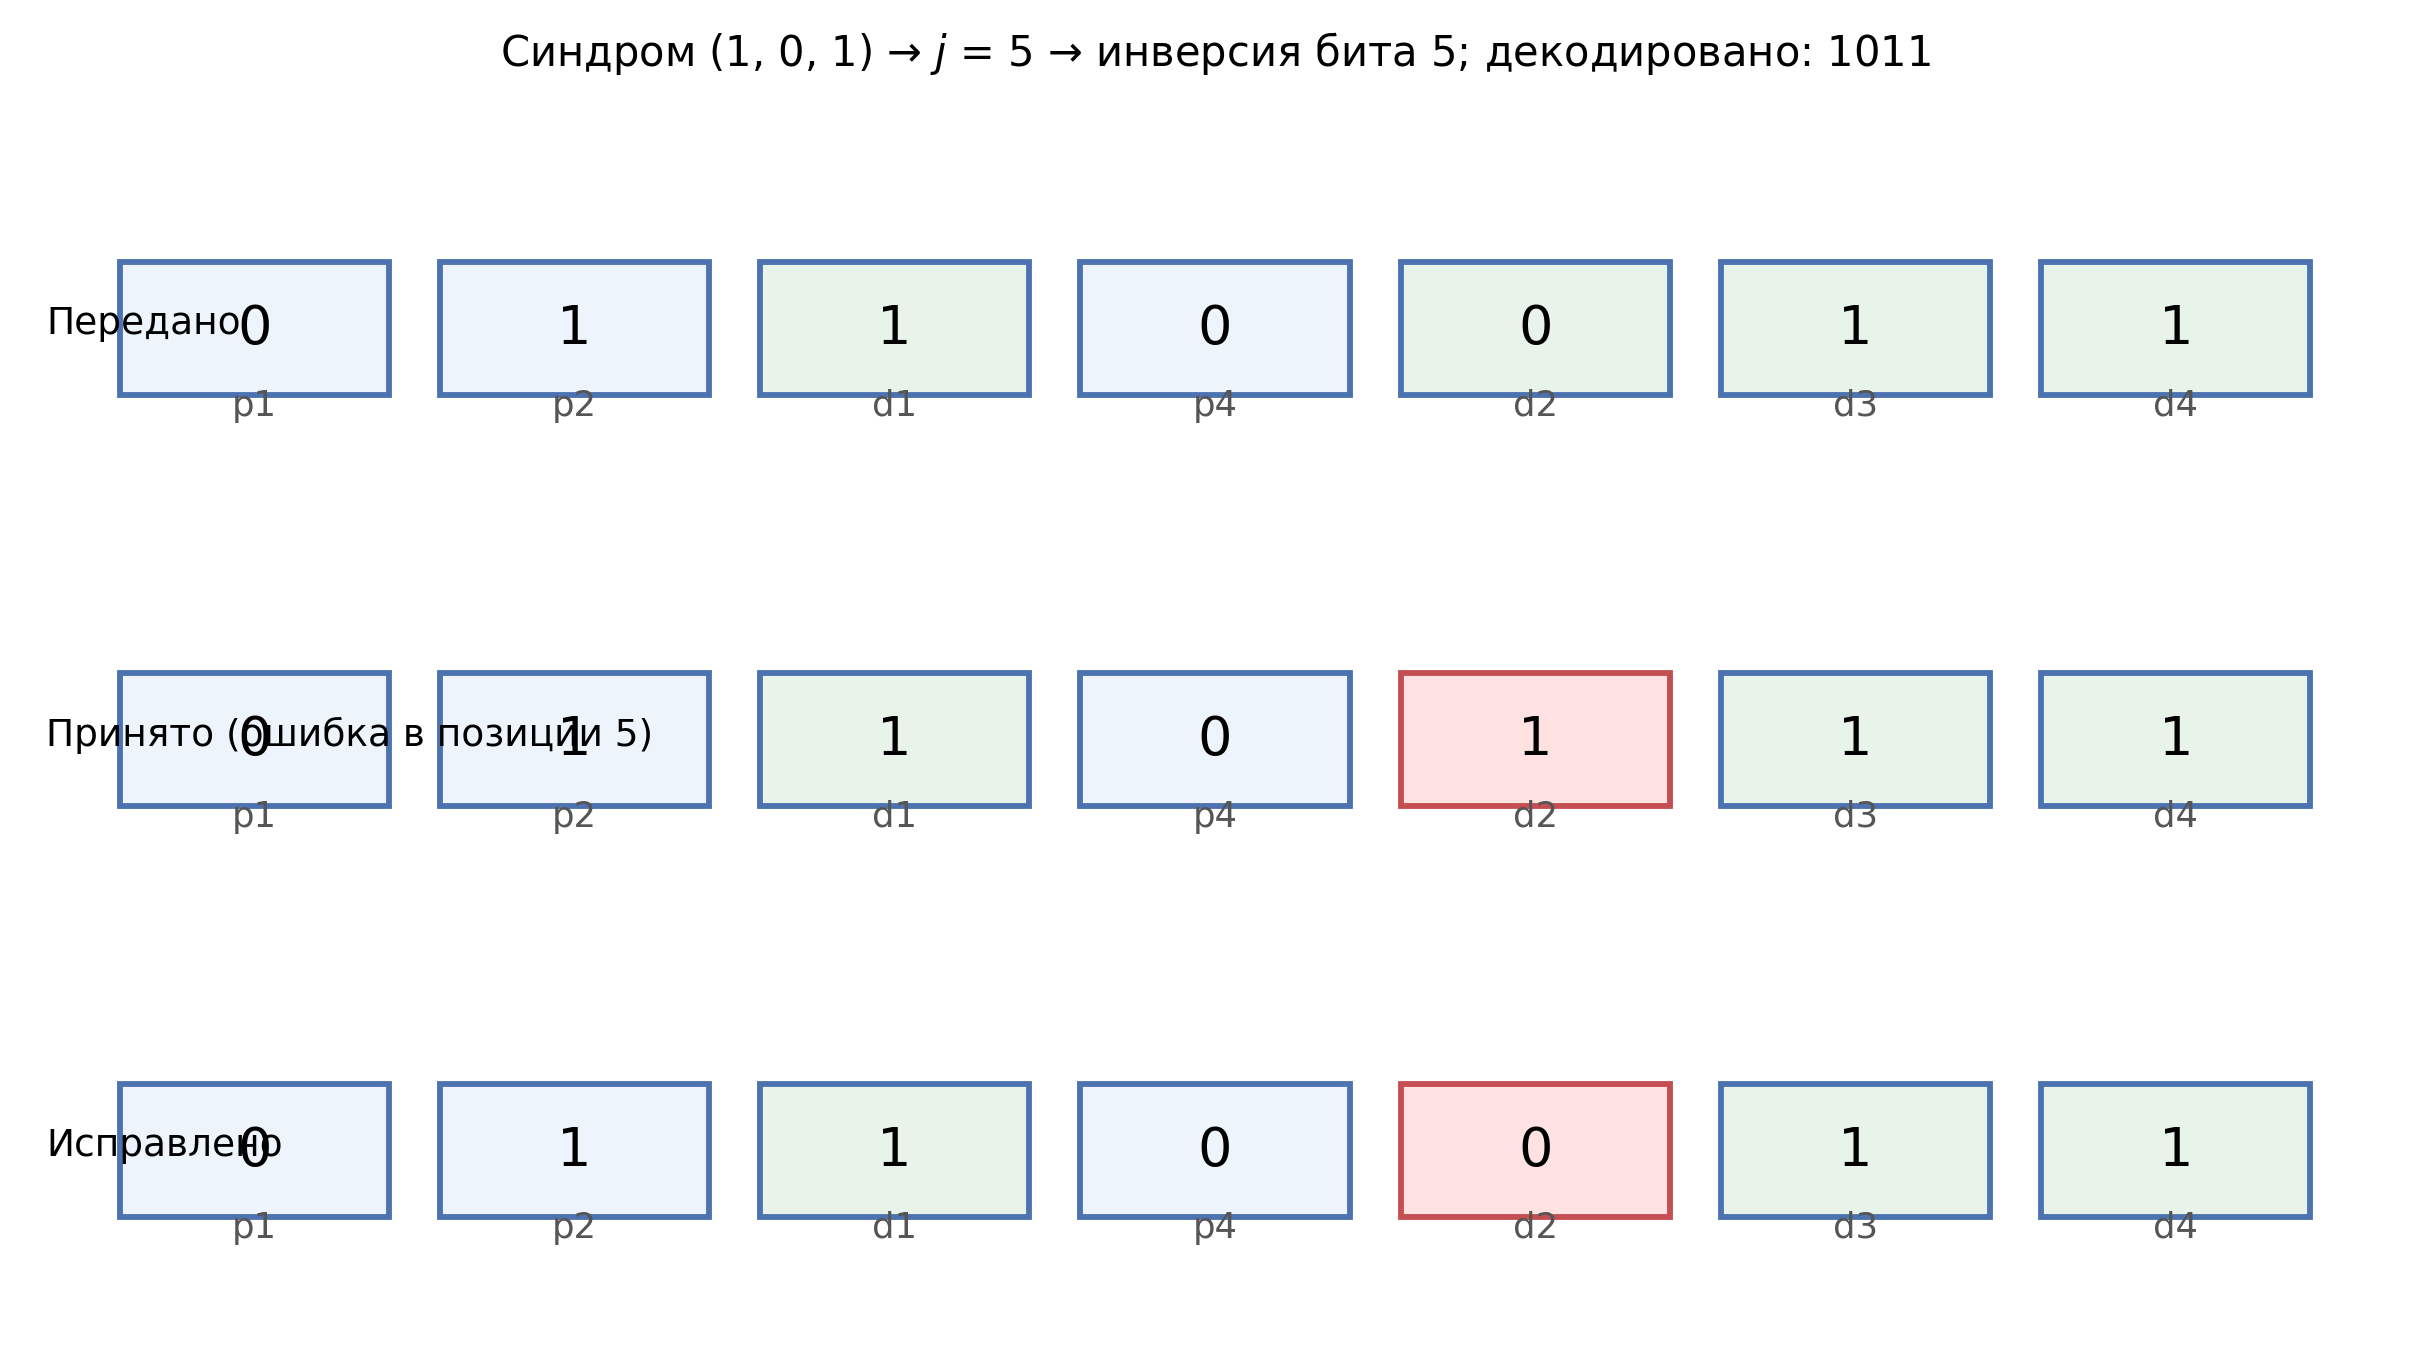

In [5]:
display(Image(filename=os.path.join(FIG, "hamming_correction.png"), width=820))

**Ограничение кода.** Гарантированно исправляется одна ошибка на слово. Если в слове две ошибки,
синдром ненулевой (нарушение проверок *обнаружено*), но число ошибок не распознаётся: двойная
ошибка интерпретируется как одиночная, декодер инвертирует «ложную» позицию и выдаёт неверную
информацию без признака отказа. Одновременное «исправить одну и обнаружить две» для этой схемы
не заявляется.

## 7. Свёрточный код $(7,5)_8$: таблица переходов и контрольные векторы

In [6]:
print("Таблица переходов (S_t, u) -> (v1v2, S_t+1):")
print(f"{'S_t':>5}{'u':>4}{'v1v2':>8}{'S_t+1':>8}")
for s, u, out, nxt in conv.TRANSITIONS:
    print(f"{s:>5}{u:>4}{out:>8}{nxt:>8}")

print("\nКонтрольные векторы (выход включает два хвостовых шага):")
print(f"{'вход':>6}{'полный вход':>14}{'выход':>16}")
for s in ["0", "1", "10", "11", "1011"]:
    bits = np.array([int(c) for c in s], dtype=np.uint8)
    full = s + "00"
    print(f"{s:>6}{full:>14}{''.join(map(str, conv.encode(bits))):>16}")
print("\nконечное состояние после кодирования:",
      set(conv.finish_state(np.array([int(c) for c in s], dtype=np.uint8)) for s in ["0","1","1011"]))

Таблица переходов (S_t, u) -> (v1v2, S_t+1):
  S_t   u    v1v2   S_t+1
    0   0      00       0
    0   1      11       2
    1   0      11       0
    1   1      00       2
    2   0      10       1
    2   1      01       3
    3   0      01       1
    3   1      10       3

Контрольные векторы (выход включает два хвостовых шага):
  вход   полный вход           выход
     0           000          000000
     1           100          111011
    10          1000        11101100
    11          1100        11010111
  1011        101100    111000010111

конечное состояние после кодирования: {0}


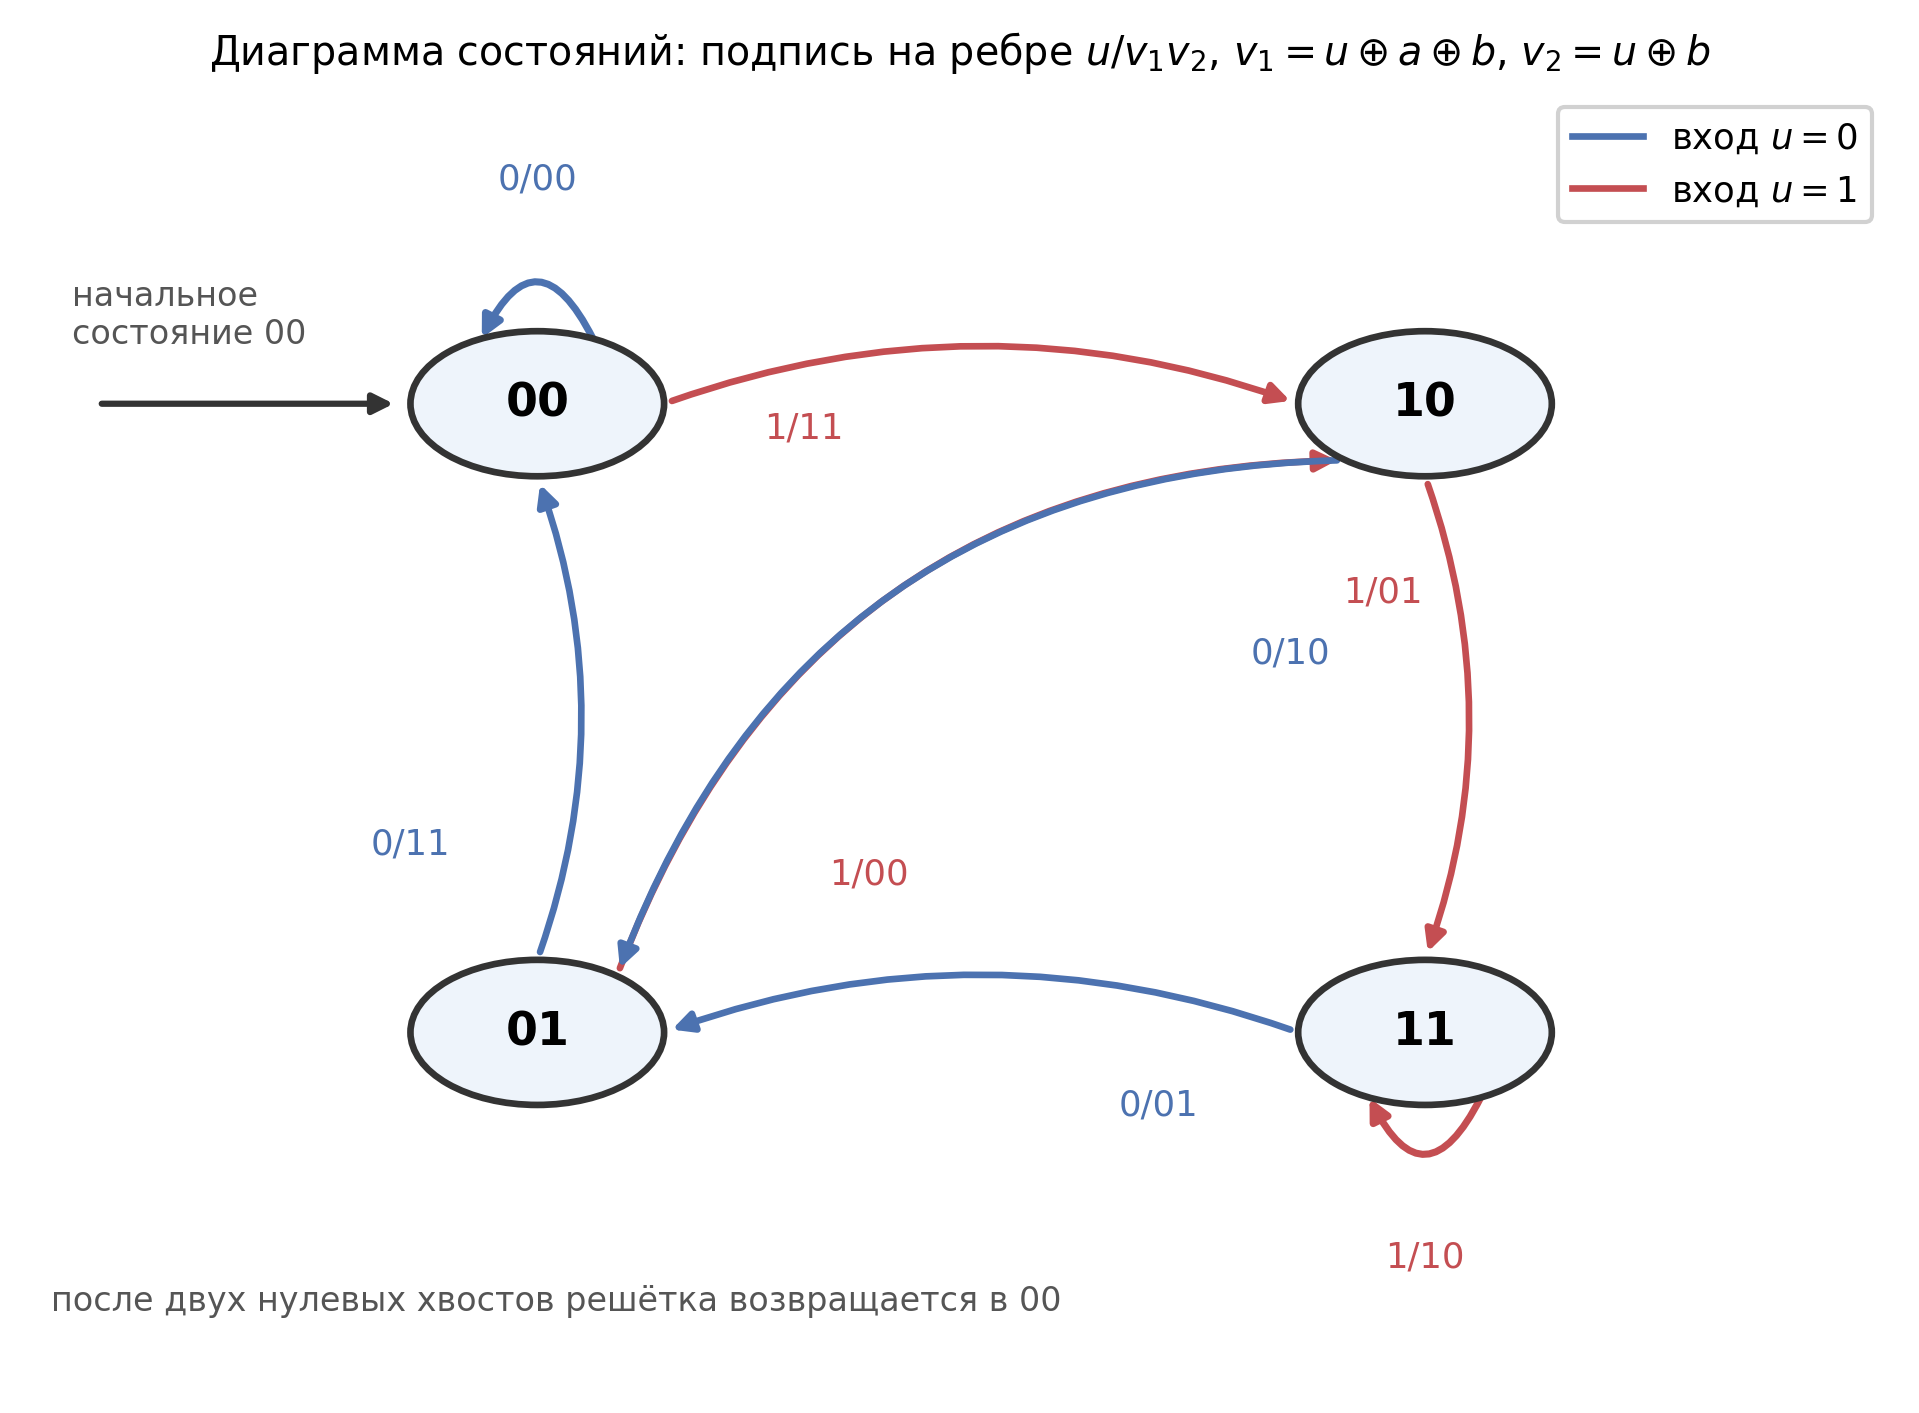

In [7]:
display(Image(filename=os.path.join(FIG, "state_diagram.png"), width=620))

## 8. Алгоритм Витерби: пример решётки и декодирования

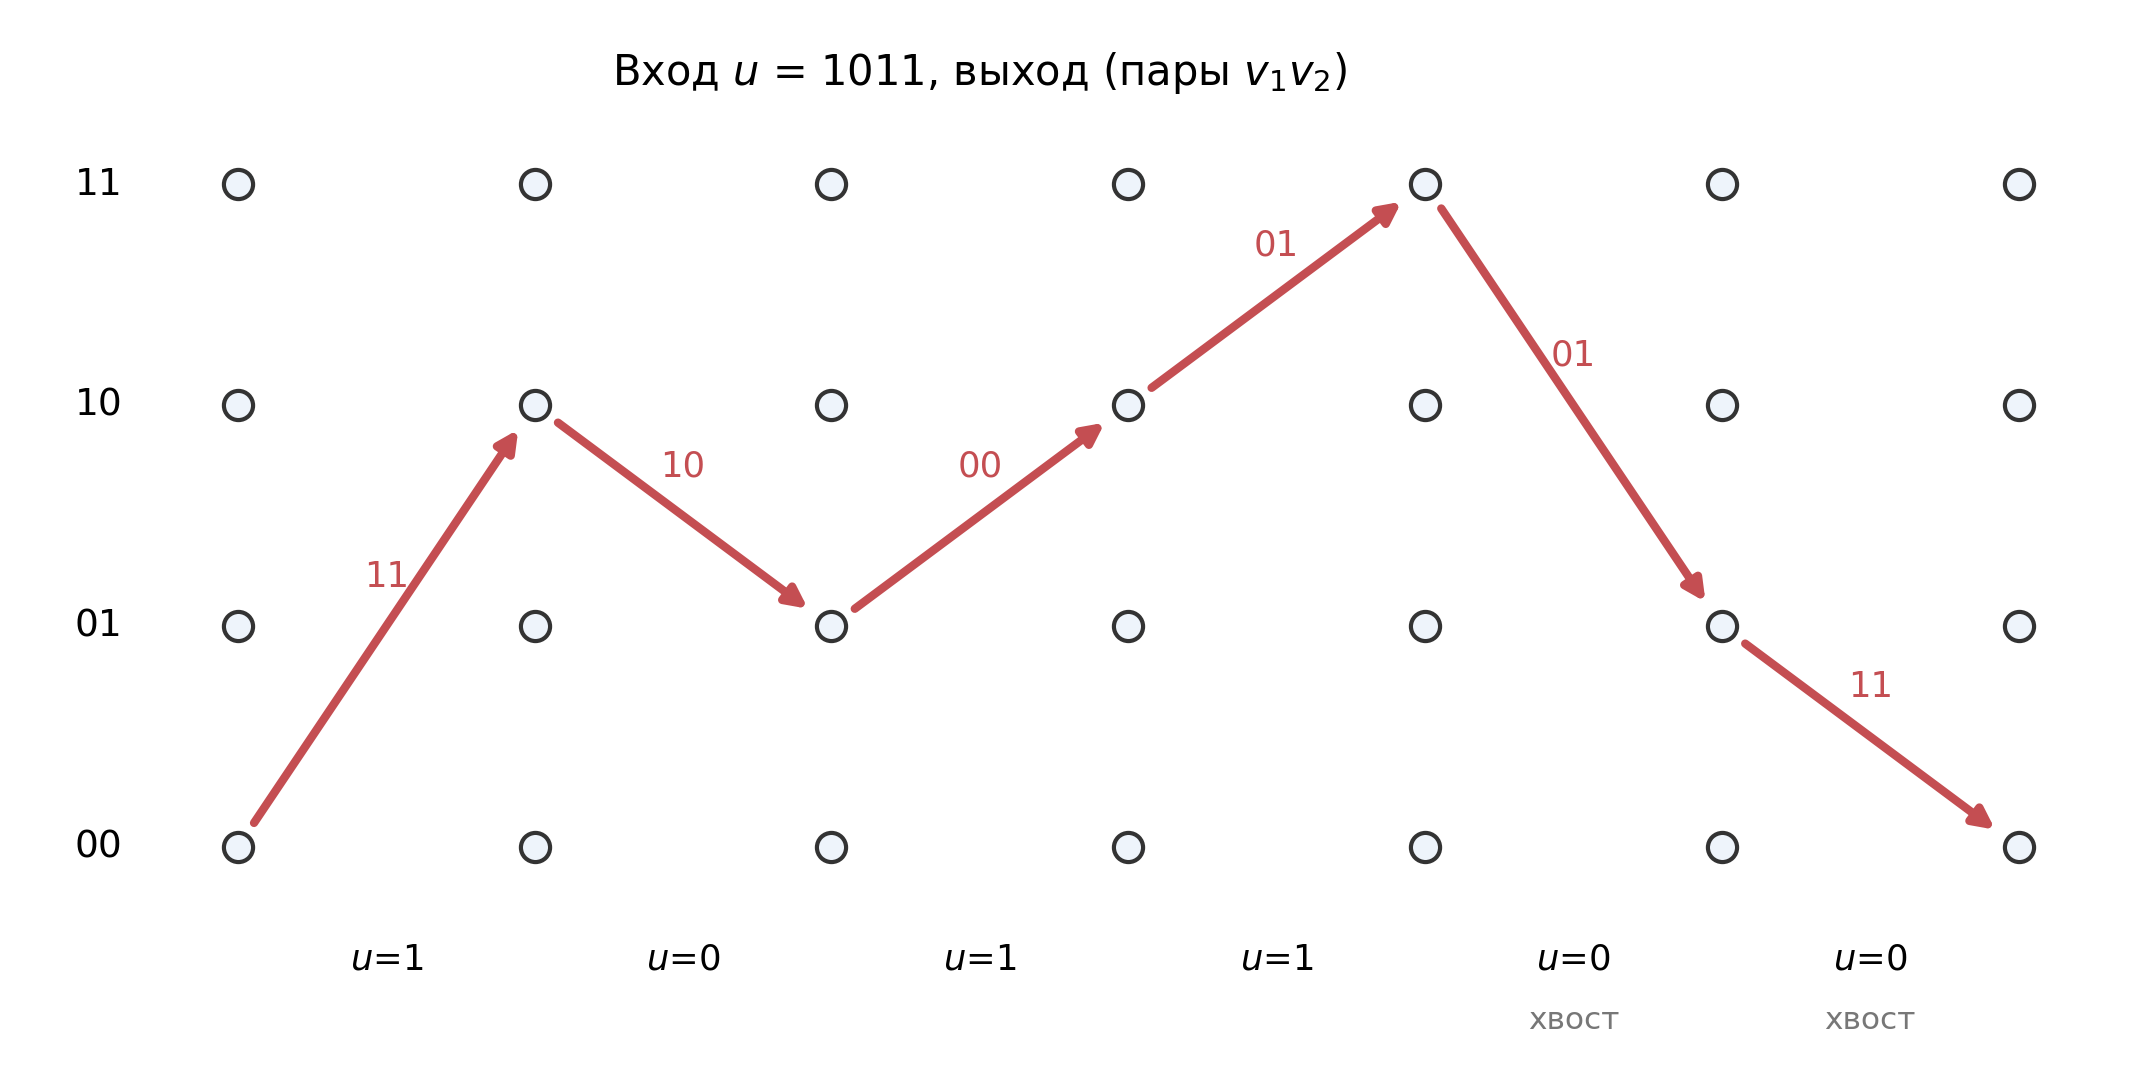

In [8]:
display(Image(filename=os.path.join(FIG, "trellis_example.png"), width=900))

In [9]:
info = np.array([1, 0, 1, 1], dtype=np.uint8)
code = conv.encode(info)
print("передано (кодовые биты):", "".join(map(str, code)))

rx = code.copy(); rx[5] ^= 1
print("принято  (1 ошибка)    :", "".join(map(str, rx)))

decoded, det = viterbi.decode(rx, length=4, return_details=True)
print("декодировано           :", "".join(map(str, decoded)))
print("итоговая метрика пути  :", int(det["final_metrics"][0]))
print("состояния S_0..S_T     :", list(map(int, det["path_state"])))
print("хвостовые входы        :", list(map(int, det["tail_input"])), "(должны быть нулями)")

передано (кодовые биты): 111000010111
принято  (1 ошибка)    : 111001010111
декодировано           : 1011
итоговая метрика пути  : 1
состояния S_0..S_T     : [0, 2, 1, 2, 3, 1, 0]
хвостовые входы        : [0, 0] (должны быть нулями)


## 9. Проверка кодеров, декодеров и канала (автоматические тесты)

Запускаются те же тесты, что и из командной строки. Они покрывают:

* Хэмминг: матрицы, 7 контрольных векторов, все 16 слов, **112 случаев одиночной ошибки**,
  ограничение по двум ошибкам, валидация входа;
* свёрточный кодер: 8 переходов, контрольные векторы, zero-tail, независимость пакетов, $d_{free}=5$;
* Витерби: без шума для всех сообщений $L\le8$, одиночные инверсии, сверка с полным перебором
  на коротких пакетах, tie-break, ширина типа метрик, батч = одиночная обработка на $L=10^4$;
* канал: BPSK, $\sigma^2$, статистика шума, эмпирическая $p$ против $Q(\sqrt{2R\gamma_b})$;
* метрики: профиль весов Хэмминга, точная формула, интервалы Клоппера—Пирсона;
* эксперимент: воспроизводимость, счётчики, запись/чтение CSV, отсутствие потери битов.

In [10]:
res = subprocess.run([sys.executable, "-m", "unittest", "discover", "-s", "tests", "-t", "."],
                     cwd=ROOT, capture_output=True, text=True)
tail = (res.stderr or "").strip().splitlines()[-3:]
print("\n".join(tail))
print("код возврата:", res.returncode)
assert res.returncode == 0, "тесты не прошли"

Ran 119 tests in 6.611s

OK
код возврата: 0


## 10. Моделирование канала AWGN: контрольные проверки

Проверяем, что:

1. дисперсия шума соответствует $\sigma^2 = 1/(2R_{eff}\gamma_b)$;
2. при одинаковом $E_b/N_0$ разные скорости требуют разной $\sigma^2$;
3. эмпирическая вероятность ошибки бита совпадает с $Q(\sqrt{2R_{eff}\gamma_b})$.

In [11]:
for x in (0.0, 3.0, 10.0):
    print(f"Eb/N0 = {x:4.1f} дБ:  sigma^2 (R=1) = {channel.variance_from_ebno(x, 1.0):.6f}   "
          f"sigma^2 (R=4/7) = {channel.variance_from_ebno(x, 4/7):.6f}   "
          f"sigma^2 (R=0.4999) = {channel.variance_from_ebno(x, 0.49990):.6f}")

rng = np.random.default_rng(2026)
n = 300_000
bits = rng.integers(0, 2, size=n, dtype=np.uint8)
for rate, name in ((1.0, "R=1"), (4/7, "R=4/7")):
    rx = channel.transmit_hard(bits, 4.0, rate, rng)
    p_emp = metrics.count_bit_errors(bits, rx) / n
    p_th = channel.bit_error_probability(4.0, rate)
    se = np.sqrt(p_th * (1 - p_th) / n)
    print(f"\nEb/N0 = 4 дБ, {name}: эмпирическая p = {p_emp:.5f}, "
          f"теория Q(sqrt(2R·gamma_b)) = {p_th:.5f}, "
          f"разница / SE = {(p_emp - p_th) / se:+.2f}")

Eb/N0 =  0.0 дБ:  sigma^2 (R=1) = 0.500000   sigma^2 (R=4/7) = 0.875000   sigma^2 (R=0.4999) = 1.000200
Eb/N0 =  3.0 дБ:  sigma^2 (R=1) = 0.250594   sigma^2 (R=4/7) = 0.438539   sigma^2 (R=0.4999) = 0.501287
Eb/N0 = 10.0 дБ:  sigma^2 (R=1) = 0.050000   sigma^2 (R=4/7) = 0.087500   sigma^2 (R=0.4999) = 0.100020

Eb/N0 = 4 дБ, R=1: эмпирическая p = 0.01253, теория Q(sqrt(2R·gamma_b)) = 0.01250, разница / SE = +0.16

Eb/N0 = 4 дБ, R=4/7: эмпирическая p = 0.04487, теория Q(sqrt(2R·gamma_b)) = 0.04510, разница / SE = -0.61


## 11. Контрольный эксперимент без кодирования

Небольшой объём (демонстрационный режим), чтобы показать процедуру и согласие с теорией.
Полный объём — в разделе 14 и в сохранённых CSV.

In [12]:
quick = simulation.Plan(n_info_uncoded=300_000, n_info_hamming=300_000,
                        n_info_convolutional=100_000, packet_length=10_000,
                        ebno_db=(0.0, 2.0, 4.0, 6.0, 8.0))

rows = []
for x in quick.ebno_db:
    r = simulation.run_point("uncoded", x, quick)
    rows.append((x, r.n_errors, r.n_info_bits, r.ber, metrics.bpsk_ber_theory(x)))
print(f"{'Eb/N0':>7}{'E':>9}{'N_info':>10}{'BER эксп.':>13}{'BER теор.':>13}{'отн.':>8}")
for x, e, n, b, t in rows:
    print(f"{x:>7.0f}{e:>9}{n:>10,}{b:>13.3e}{t:>13.3e}{b/t:>8.3f}")

  Eb/N0        E    N_info    BER эксп.    BER теор.    отн.
      0    23564   300,000    7.855e-02    7.865e-02   0.999
      2    11248   300,000    3.749e-02    3.751e-02   1.000
      4     3738   300,000    1.246e-02    1.250e-02   0.997
      6      746   300,000    2.487e-03    2.388e-03   1.041
      8       59   300,000    1.967e-04    1.909e-04   1.030


## 12. Эксперимент с кодом Хэмминга (7,4)

In [13]:
rows_h = []
for x in quick.ebno_db:
    r = simulation.run_point("hamming", x, quick)
    rows_h.append((x, r))
print(f"{'Eb/N0':>7}{'E':>9}{'BER эксп.':>13}{'BER теор.':>13}{'отн.':>8}{'M':>9}{'K':>8}")
for x, r in rows_h:
    th = metrics.hamming_ber_theory(x)
    print(f"{x:>7.0f}{r.n_errors:>9}{r.ber:>13.3e}{th:>13.3e}{r.ber/th:>8.3f}"
          f"{r.n_units:>9,}{r.n_units_with_errors:>8,}")
print("\nM — число блоков, K — число блоков с ошибками (независимые единицы).")

  Eb/N0        E    BER эксп.    BER теор.    отн.        M       K
      0    35682    1.189e-01    1.192e-01   0.998   75,000  19,798
      2    16320    5.440e-02    5.496e-02   0.990   75,000   9,247
      4     4905    1.635e-02    1.604e-02   1.019   75,000   2,776
      6      694    2.313e-03    2.325e-03   0.995   75,000     391
      8       42    1.400e-04    1.169e-04   1.198   75,000      24

M — число блоков, K — число блоков с ошибками (независимые единицы).


## 13. Эксперимент со свёрточным кодом и Витерби

In [14]:
rows_c = []
for x in quick.ebno_db:
    r = simulation.run_point("convolutional", x, quick)
    rows_c.append((x, r))
print(f"{'Eb/N0':>7}{'E':>8}{'BER':>12}{'пакетов M':>11}{'K (с ошибками)':>16}"
      f"{'бит/пакет':>11}{'время, с':>10}")
for x, r in rows_c:
    print(f"{x:>7.0f}{r.n_errors:>8}{r.ber:>12.3e}{r.n_units:>11}{r.n_units_with_errors:>16}"
          f"{r.ber * r.ell:>11.1f}{r.elapsed_s:>10.1f}")
print("\nЗдесь важно не только E: 100 ошибок внутри одного пакета — это одно независимое событие.")

  Eb/N0       E         BER  пакетов M  K (с ошибками)  бит/пакет  время, с
      0   20077   2.008e-01         10              10     2007.7       0.2
      2    7568   7.568e-02         10              10      756.8       0.2
      4    1207   1.207e-02         10              10      120.7       0.2
      6      78   7.800e-04         10               9        7.8       0.2
      8       0   0.000e+00         10               0        0.0       0.2

Здесь важно не только E: 100 ошибок внутри одного пакета — это одно независимое событие.


In [15]:
# кластерные интервалы: точный расчёт по сохранённым гистограммам Z_j
import csv as _csv
cl_path = os.path.join(DATA, "cluster_intervals.csv")
with open(cl_path, newline="", encoding="utf-8") as f:
    cl = list(_csv.DictReader(f))
print(f"{'схема':<15}{'Eb/N0':>6}{'E':>9}{'K':>9}{'SE':>11}"
      f"{'кластерный 95 %':>26}{'консервативный 95 %':>26}")
for row in cl:
    if row["dataset"] != "extended":
        continue
    if float(row["ebno_db"]) not in (6.0, 7.0, 8.0):
        continue
    scheme = {"uncoded": "без кода", "hamming": "Хэмминг",
              "convolutional": "Витерби"}[row["scheme"]]
    lo, hi = float(row["cluster_ci_low"]), float(row["cluster_ci_high"])
    cluster = (f"[{lo:.3e}, {hi:.3e}]" if row["cluster_applicable"] == "1"
               else "не применим (K<30)")
    cons = (f"[{float(row['conservative_ci_low']):.3e}, "
            f"{float(row['conservative_ci_high']):.3e}]"
            if float(row["conservative_ci_high"]) > 0 else "—")
    print(f"{scheme:<15}{float(row['ebno_db']):>6.0f}{int(row['E']):>9,}"
          f"{int(row['K']):>9,}{float(row['SE']):>11.2e}{cluster:>26}{cons:>26}")
print()
print("Кластерный интервал учитывает разброс числа ошибок по независимым единицам;")
print("консервативный интервал по построению шире, но не требует нормальной аппроксимации.")

схема           Eb/N0        E        K         SE           кластерный 95 %       консервативный 95 %
без кода            6   47,899   47,899   1.09e-05    [2.374e-03, 2.416e-03]    [2.374e-03, 2.416e-03]
без кода            7   15,493   15,493   6.22e-06    [7.625e-04, 7.868e-04]    [7.625e-04, 7.869e-04]
без кода            8    3,829    3,829   3.09e-06    [1.854e-04, 1.975e-04]    [1.854e-04, 1.976e-04]
Хэмминг             6   46,427   26,855   1.53e-05    [2.291e-03, 2.351e-03]    [1.327e-03, 5.435e-03]
Хэмминг             7   12,407    7,210   7.88e-06    [6.049e-04, 6.358e-04]    [3.522e-04, 1.476e-03]
Хэмминг             8    2,442    1,424   3.49e-06    [1.153e-04, 1.289e-04]    [6.755e-05, 3.000e-04]
Витерби             6    6,338      954   1.27e-05    [6.089e-04, 6.587e-04]    [9.391e-05, 9.661e-01]
Витерби             7      949      405   4.71e-06    [8.567e-05, 1.041e-04]    [3.744e-05, 4.362e-01]
Витерби             8      129       75   1.53e-06    [9.911e-06, 1.589e-

## 14. Сравнительный график BER($E_b/N_0$)

График строится **из сохранённых CSV** (основной прогон — залитые маркеры,
расширенный объём — полые маркеры, теория — штриховые линии).
Точки, где ошибок не наблюдалось, показаны стрелкой вниз от консервативной верхней границы.

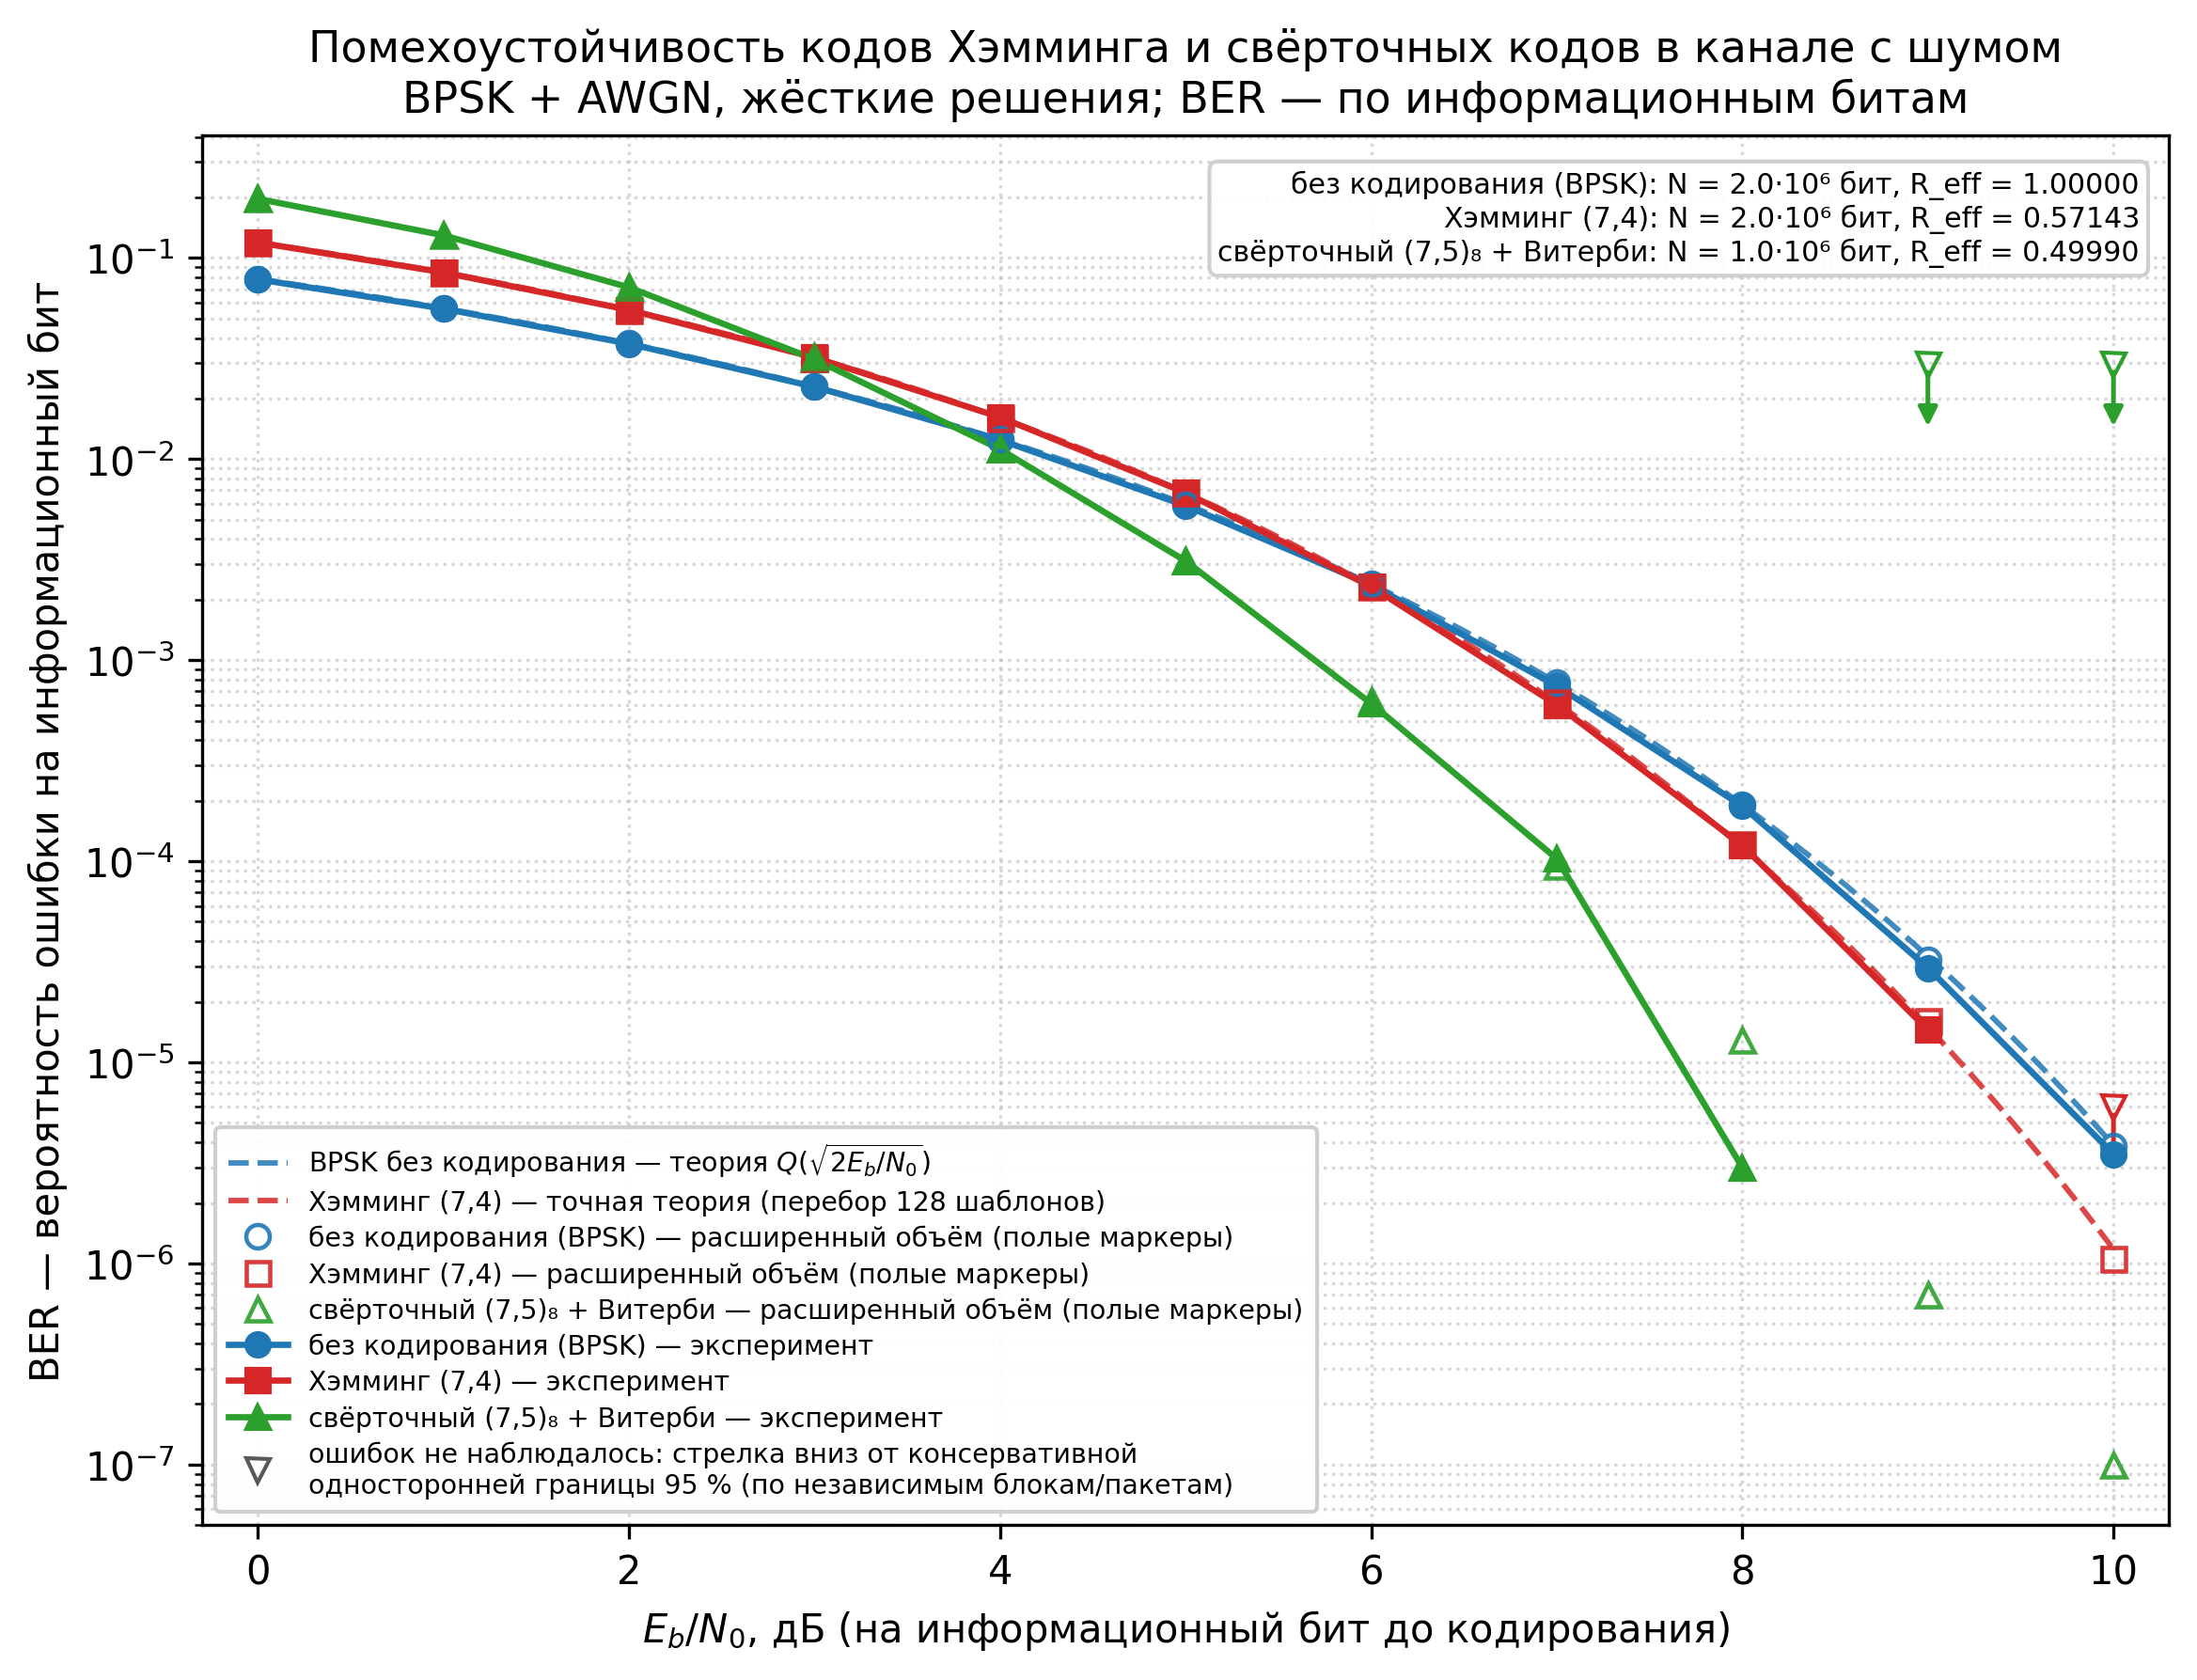

In [16]:
main_csv = os.path.join(DATA, "ber_results.csv")
supp_csv = os.path.join(DATA, "ber_results_extended.csv")
theory_csv = os.path.join(DATA, "theory_curves.csv")

paths = plotting.ber_curve_plot(main_csv, theory_csv, FIG,
                                supp_csv=supp_csv if os.path.exists(supp_csv) else None)
display(Image(filename=os.path.join(FIG, "ber_comparison.png"), width=980))

Таблица сохранённых результатов (расширенный объём, `ber_results_extended.csv`) —
с числом переданных битов, ошибок и интервалами:

In [17]:
ext = plotting.read_csv(supp_csv) if os.path.exists(supp_csv) else plotting.read_csv(main_csv)
names = {"uncoded": "без кодирования", "hamming": "Хэмминг (7,4)",
         "convolutional": "свёрточный (7,5)₈"}
print(f"{'схема':<16}{'Eb/N0':>7}{'N_info':>12}{'E':>9}{'BER':>12}"
      f"{'M':>10}{'K':>9}{'нижняя 95%':>13}{'верхняя 95%':>14}")
for scheme in ("uncoded", "hamming", "convolutional"):
    for r in sorted((r for r in ext if r["scheme"] == scheme), key=lambda r: r["ebno_db"]):
        low = r["ci_low"] if r["ber"] > 0 else float("nan")
        high = r["ci_high"] if r["ber"] > 0 else r["upper95"]
        print(f"{names[scheme]:<16}{r['ebno_db']:>7.0f}{int(r['n_info_bits']):>12,}"
              f"{int(r['n_errors']):>9,}{r['ber']:>12.3e}{int(r['n_units']):>10,}"
              f"{int(r['n_units_with_errors']):>9,}{low:>13.2e}{high:>14.2e}")

схема             Eb/N0      N_info        E         BER         M        K   нижняя 95%   верхняя 95%
без кодирования       0  20,000,0001,573,247   7.866e-0220,000,0001,573,247     7.85e-02      7.88e-02
без кодирования       1  20,000,0001,126,737   5.634e-0220,000,0001,126,737     5.62e-02      5.64e-02
без кодирования       2  20,000,000  750,518   3.753e-0220,000,000  750,518     3.74e-02      3.76e-02
без кодирования       3  20,000,000  458,040   2.290e-0220,000,000  458,040     2.28e-02      2.30e-02
без кодирования       4  20,000,000  250,351   1.252e-0220,000,000  250,351     1.25e-02      1.26e-02
без кодирования       5  20,000,000  118,864   5.943e-0320,000,000  118,864     5.91e-03      5.98e-03
без кодирования       6  20,000,000   47,899   2.395e-0320,000,000   47,899     2.37e-03      2.42e-03
без кодирования       7  20,000,000   15,493   7.746e-0420,000,000   15,493     7.63e-04      7.87e-04
без кодирования       8  20,000,000    3,829   1.914e-0420,000,000    3,8

## 15. Энергетический выигрыш

Выигрыш — горизонтальное расстояние между кривыми при фиксированном BER:
$\Delta = E_b/N_0^{uncoded}(P^*) - E_b/N_0^{coded}(P^*)$, интерполяция линейная по
$\lg(\mathrm{BER})$, без экстраполяции. Данные читаются из `results/data/energy_gain.csv`.

In [18]:
import csv as _csv
gain_path = os.path.join(DATA, "energy_gain.csv")
with open(gain_path, newline="", encoding="utf-8") as f:
    grows = list(_csv.DictReader(f))

print(f"{'набор':<10}{'схема':<14}{'BER*':>7}{'без кода':>10}{'код':>8}"
      f"{'выигрыш':>9}{'bootstrap 95 %':>20}  диагностика")
for g in grows:
    xa = f"{float(g['x_uncoded_db']):.2f}" if g["x_uncoded_db"] else "—"
    xb = f"{float(g['x_coded_db']):.2f}" if g["x_coded_db"] else "—"
    gd = f"{float(g['gain_point_db']):+.2f}" if g["gain_point_db"] else "н/д"
    if g["gain_ci_low_db"] and g["gain_ci_high_db"]:
        ci = f"[{float(g['gain_ci_low_db']):+.2f}; {float(g['gain_ci_high_db']):+.2f}]"
    else:
        ci = "не оценена"
    diag = []
    if g["e_ge_100"] != "1":
        diag.append("E<100")
    if g["k_ge_30"] != "1":
        diag.append("K<30")
    print(f"{g['dataset']:<10}{g['scheme']:<14}{float(g['target_ber']):>7.0e}"
          f"{xa:>10}{xb:>8}{gd:>9}{ci:>20}  {', '.join(diag) or '—'}")
print()
print("Выигрыш — точечная оценка по интерполяции сетки 1 дБ; bootstrap — приближённый,")
print("не устраняет погрешность сетки. Отрицательный выигрыш = проигрыш кодирования.")

набор     схема            BER*  без кода     код  выигрыш      bootstrap 95 %  диагностика
extended  hamming         1e-02      4.30    4.55    -0.25          не оценена  —
extended  hamming         1e-03      6.77    6.64    +0.14          не оценена  —
extended  hamming         1e-04      8.37    8.10    +0.27      [+0.24; +0.30]  —
extended  hamming         1e-05      9.55    9.17    +0.38          не оценена  E<100, K<30
extended  convolutional   1e-02      4.30    4.10    +0.20          не оценена  —
extended  convolutional   1e-03      6.77    5.71    +1.06          не оценена  —
extended  convolutional   1e-04      8.37    6.97    +1.39      [+1.34; +1.45]  —
extended  convolutional   1e-05      9.55    8.09    +1.46          не оценена  E<100, K<30
main      hamming         1e-02      4.29    4.55    -0.26          не оценена  —
main      hamming         1e-03      6.75    6.62    +0.12          не оценена  —
main      hamming         1e-04      8.34    8.09    +0.25      [+0.

## 16. Анализ результатов

Ниже — величины, извлечённые из сохранённых данных; качественные выводы сформулированы
в разделе 17. Интерпретация и научные формулировки — зона ответственности Агента №2.

In [19]:
def curve(rows, scheme):
    return {r["ebno_db"]: r["ber"] for r in rows if r["scheme"] == scheme and r["ber"] > 0}

unc, ham, cnv = (curve(ext, s) for s in ("uncoded", "hamming", "convolutional"))

print("Порядок кривых при высоком Eb/N0 (меньше — лучше):")
for x in (8.0, 9.0, 10.0):
    vals = {"без кодирования": unc.get(x), "Хэмминг (7,4)": ham.get(x),
            "свёрточный": cnv.get(x)}
    order = sorted(vals, key=lambda k: vals[k])
    print(f"  {x:4.0f} дБ: " + " < ".join(
        f"{k} ({vals[k]:.1e})" if vals[k] else k for k in order))

print("\nГде кодирование начинает выигрывать (пересечение с кривой без кодирования):")
for name, c in (("Хэмминг (7,4)", ham), ("свёрточный", cnv)):
    xs = sorted(set(unc) & set(c))
    cross = None
    for a, b in zip(xs, xs[1:]):
        d1 = unc[a] - c[a]
        d2 = unc[b] - c[b]
        if d1 * d2 < 0:
            cross = a + (b - a) * abs(d1) / (abs(d1) + abs(d2))
            break
    print(f"  {name:<16} ≈ {cross:.2f} дБ" if cross else f"  {name}: в пределах сетки не пересекается")

print("\nОтношение BER кодированной схемы к BER без кодирования:")
print(f"{'Eb/N0':>7}{'Хэмминг':>12}{'свёрточный':>14}")
for x in sorted(set(unc) & set(ham) & set(cnv)):
    print(f"{x:>7.0f}{unc[x]/ham[x]:>12.2f}{unc[x]/cnv[x]:>14.2f}")

Порядок кривых при высоком Eb/N0 (меньше — лучше):
     8 дБ: свёрточный (1.3e-05) < Хэмминг (7,4) (1.2e-04) < без кодирования (1.9e-04)
     9 дБ: свёрточный (7.0e-07) < Хэмминг (7,4) (1.6e-05) < без кодирования (3.2e-05)
    10 дБ: свёрточный (1.0e-07) < Хэмминг (7,4) (1.0e-06) < без кодирования (3.9e-06)

Где кодирование начинает выигрывать (пересечение с кривой без кодирования):
  Хэмминг (7,4)    ≈ 5.92 дБ
  свёрточный       ≈ 3.89 дБ

Отношение BER кодированной схемы к BER без кодирования:
  Eb/N0     Хэмминг    свёрточный
      0        0.66          0.40
      1        0.67          0.43
      2        0.68          0.52
      3        0.72          0.71
      4        0.78          1.10
      5        0.87          1.89
      6        1.03          3.78
      7        1.25          8.16
      8        1.57         14.84
      9        2.03         46.29
     10        3.67         38.50


In [20]:
zero = [r for r in ext if r["n_errors"] == 0]
print("Точки без наблюдаемых ошибок:")
if not zero:
    print("  таких нет")
for r in sorted(zero, key=lambda r: (r["scheme"], r["ebno_db"])):
    print(f"  {names[r['scheme']]:<16} {r['ebno_db']:4.0f} дБ: M = {int(r['n_units']):,}, "
          f"BER = 0 (наблюдаемая доля), верхняя граница 95 % = {r['upper95']:.2e}")
print("\nТакие точки не изображаются как BER = 0 и не участвуют в интерполяции.")

Точки без наблюдаемых ошибок:
  таких нет

Такие точки не изображаются как BER = 0 и не участвуют в интерполяции.


### 16.1. Уточняющий прогон по сетке 0.2 дБ

Сетка 0.2 дБ вокруг $10^{-4}$ запущена отдельным прогоном после согласования объёма
(seed 20261026, план зафиксирован до запуска). Результаты **не объединяются** с основными:
это отдельный набор `ber_refinement.csv`.

In [21]:
ref_csv = os.path.join(DATA, "ber_refinement.csv")
if not os.path.exists(ref_csv):
    print("нет ber_refinement.csv — запустите: python scripts/run_refinement.py")
else:
    ref = plotting.read_csv(ref_csv)
    print(f"{'схема':<16}{'Eb/N0':>7}{'BER':>12}{'K':>7}  кластерный 95 %")
    for r in sorted(ref, key=lambda r: (r["scheme"], r["ebno_db"])):
        print(f"{names[r['scheme']]:<16}{r['ebno_db']:>7.1f}{r['ber']:>12.3e}"
              f"{int(r['n_units_with_errors']):>7}  "
              f"[{r['cluster_low']:.3e}, {r['cluster_high']:.3e}]")

    gpath = os.path.join(DATA, "refinement_gains.csv")
    if os.path.exists(gpath):
        print("\nВыигрыш при BER = 1e-4 (bootstrap 10 000 реплик, seed 777001;")
        print("набор: refinement_0p2db — сетка 0.2 дБ, extended_1db — сетка 1 дБ):")
        for g in plotting.read_csv(gpath):
            print(f"  {g.get('dataset',''):<16} {names[g['scheme']]:<16} "
                  f"{float(g['gain_point_db']):+.2f} дБ  "
                  f"[{float(g['gain_ci_low_db']):+.2f}; {float(g['gain_ci_high_db']):+.2f}]  "
                  f"невалидных {float(g['invalid_fraction'])*100:.0f} %  "
                  f"смена пары {float(g['pair_changed_fraction'])*100:.0f} %")

схема             Eb/N0         BER      K  кластерный 95 %
свёрточный (7,5)₈    6.6   2.319e-04    708  [2.175e-04, 2.463e-04]
свёрточный (7,5)₈    6.8   1.601e-04    574  [1.480e-04, 1.722e-04]
свёрточный (7,5)₈    7.0   1.048e-04    421  [9.509e-05, 1.145e-04]
свёрточный (7,5)₈    7.2   6.900e-05    301  [6.100e-05, 7.700e-05]
свёрточный (7,5)₈    7.4   4.370e-05    217  [3.769e-05, 4.971e-05]
Хэмминг (7,4)       7.8   1.708e-04   2926  [1.641e-04, 1.775e-04]
Хэмминг (7,4)       8.0   1.199e-04   2051  [1.143e-04, 1.255e-04]
Хэмминг (7,4)       8.2   8.050e-05   1377  [7.591e-05, 8.509e-05]
Хэмминг (7,4)       8.4   5.500e-05    931  [5.119e-05, 5.881e-05]
Хэмминг (7,4)       8.6   3.643e-05    626  [3.335e-05, 3.952e-05]
без кодирования     8.0   1.919e-04   5758  [1.870e-04, 1.969e-04]
без кодирования     8.2   1.405e-04   4216  [1.363e-04, 1.448e-04]
без кодирования     8.4   1.013e-04   3040  [9.773e-05, 1.049e-04]
без кодирования     8.6   7.140e-05   2142  [6.838e-05, 7.442e-0

### 16.2. Сеточная ошибка процедуры и разница интерполяции

На точных теоретических кривых измерено, какую ошибку вносит сама дискретизация сетки
при поиске пересечения с уровнем $10^{-4}$ (точка пересечения ищется на той же сетке,
что и в эксперименте):

* BPSK: точный корень 8.3983 дБ, сетка 1 дБ даёт 8.3724 дБ (−0.0259), сетка 0.2 дБ — 8.3982 дБ;
* Хэмминг (7,4): точный корень 8.0841 дБ, сетка 1 дБ даёт 8.0761 дБ (−0.0080), 0.2 дБ — 8.0831 дБ.

Разница между результатами двух способов интерполяции (лог-линейная по сетке 1 дБ против
сетки 0.2 дБ) составляет **0.10 дБ** для Хэмминга и **0.19 дБ** для свёрточного кода.
Это разница способов интерполяции, а не статистическая погрешность; с bootstrap-интервалом
она не складывается.

**Что показывают данные (формулировки, требующие согласования с Агентом №2):**

* при малых $E_b/N_0$ (0…3 дБ) обе кодированные схемы **проигрывают** передаче без кодирования:
  энергетический проигрыш от введения избыточности превышает выигрыш от исправления ошибок;
* начиная примерно с 4 дБ кривые пересекаются, и далее кодирование даёт выигрыш,
  растущий с уменьшением BER;
* код Хэмминга (7,4) с жёстким декодированием даёт **малый** выигрыш (порядка десятых долей дБ
  на уровне $10^{-4}$), что соответствует его небольшому $d_{min}=3$ и скорости $4/7$
  (потеря $10\lg(7/4)\approx2.43$ дБ относительно передачи без кодирования);
* свёрточный код $(7,5)_8$ с Витерби даёт заметно больший выигрыш (порядка 1.3–1.4 дБ на $10^{-4}$)
  при $d_{free}=5$; цена скорости $R\approx1/2$ составляет около 3 дБ (объяснять разницу
  только значениями $d_{min}=3$ и $d_{free}=5$ нельзя: важны скорости, спектр событий
  ошибок и способ декодирования);
* статистическая неопределённость выигрыша оценена кластерным bootstrap по 10 000 репликам
  (ресэмплирование независимых блоков/пакетов, seed 777001): при BER $=10^{-4}$ интервалы
  составляют примерно $\pm0.03$ дБ для Хэмминга и $\pm0.05$ дБ для свёрточного кода; это
  **не** включает сеточную ошибку, которая для Хэмминга на сетке 1 дБ сопоставима с самим
  эффектом — поэтому и выполнен отдельный прогон по сетке 0.2 дБ;
* все результаты получены для **жёстких** решений; мягкие решения здесь не моделировались,
  поэтому численная оценка их преимущества не приводится.

## 17. Выводы

1. Реализованы и проверены независимыми тестами кодер Хэмминга (7,4), свёрточный кодер
   $(7,5)_8$ с нулевым завершением решётки и декодер Витерби для жёстких решений;
   сторонние библиотеки помехоустойчивого кодирования не использовались.
2. Модель канала BPSK + AWGN реализована с нормировкой энергии на **информационный бит**
   через фактическую скорость $R_{eff}$, включая штраф за хвостовые биты; согласие
   эксперимента с теорией проверено в пределах статистической погрешности.
3. BER считается по информационным битам, число переданных битов фиксируется для каждой
   схемы и точки; потери битов нет (проверено тестами).
4. На уровне BER $=10^{-4}$ свёрточный код $(7,5)_8$ с Витерби даёт выигрыш, округлённый
   до 0.1 дБ, **+1.4 дБ** относительно передачи без кодирования, код Хэмминга (7,4) —
   **+0.3 дБ** (жёсткие решения; уточняющая сетка 0.2 дБ: +0.32 и +1.39 дБ,
   bootstrap-интервалы 10 000 реплик).
5. При $E_b/N_0 \lesssim 4$ дБ кодирование проигрывает: избыточность снижает энергию на
   информационный бит сильнее, чем даёт исправление ошибок.
6. Точки, где ошибок не наблюдалось, приведены с консервативной верхней границей 95 %
   по независимым единицам, а не с BER = 0.
7. Достигнутая статистика зафиксирована честно: число ошибок, число независимых единиц,
   интервалы и статус каждой точки сохранены в CSV; там, где статистики недостаточно,
   это указано (см. столбец «качество» в таблице энергетического выигрыша).

## 18. Ограничения исследования

1. Рассматривались только два кода и только **жёсткое** декодирование; мягкие решения,
   другие коды и итеративное декодирование не исследовались.
2. Канал — идеальный AWGN без замираний, без стираний, без ошибок синхронизации.
3. Теоретическая кривая построена для некодированной BPSK и для точной BER Хэмминга;
   для свёрточного кода теоретическая граница не строилась (по решению Агента №2),
   поэтому его кривая — только экспериментальная.
4. Интервалы для кодированных схем консервативны по построению и могут быть очень широкими;
   кластерная нормальная оценка при $K\geq30$ — отдельный приближённый вид оценки.
5. Выводы относятся к заданным параметрам ($L=10^4$, код (7,5)₈, $K=3$); перенос на другие
   длины пакетов и полиномы требует отдельного моделирования.

## 19. Параметры воспроизводимости

Все параметры, необходимые для повторения результата, зафиксированы в коде и в CSV.

In [22]:
print("seed                 :", plan.seed)
print("диапазон Eb/N0, дБ   :", f"{plan.ebno_db[0]:.0f} … {plan.ebno_db[-1]:.0f}, шаг 1")
print("N_info (основной)    : uncoded", f"{plan.n_info_uncoded:,}",
      "| hamming", f"{plan.n_info_hamming:,}",
      "| convolutional", f"{plan.n_info_convolutional:,}")
print("пакет свёрточного    : L =", plan.packet_length, "хвост =", conv.TAIL, "бита")
print("R_eff                :", {k: round(v, 6) for k, v in plan.r_eff.items()})
print("правило завершения   : zero-tail, каждый пакет независимо из состояния 00")
print("tie-break Витерби    : меньший номер предыдущего состояния")
print("источник случайности : numpy.random.default_rng, потоки через SeedSequence")
print("доверительный уровень:", plan.confidence)
print("версии               : Python", platform.python_version(),
      "| NumPy", np.__version__, "| Matplotlib", matplotlib.__version__)
print("\nфайлы результатов:")
for name in ("ber_results.csv", "ber_results_extended.csv", "ber_refinement.csv",
             "refinement_gains.csv", "theory_curves.csv",
             "energy_gain.csv", "cluster_intervals.csv", "performance_probe.json"):
    path = os.path.join(DATA, name)
    print(f"  {name:<28} {'есть' if os.path.exists(path) else 'НЕТ'}"
          f"  ({os.path.getsize(path)} байт)" if os.path.exists(path) else
          f"  {name:<28} НЕТ")

seed                 : 20261024
диапазон Eb/N0, дБ   : 0 … 10, шаг 1
N_info (основной)    : uncoded 2,000,000 | hamming 2,000,000 | convolutional 1,000,000
пакет свёрточного    : L = 10000 хвост = 2 бита
R_eff                : {'uncoded': 1.0, 'hamming': 0.571429, 'convolutional': 0.4999}
правило завершения   : zero-tail, каждый пакет независимо из состояния 00
tie-break Витерби    : меньший номер предыдущего состояния
источник случайности : numpy.random.default_rng, потоки через SeedSequence
доверительный уровень: 0.95
версии               : Python 3.13.16 | NumPy 2.3.5 | Matplotlib 3.10.9

файлы результатов:
  ber_results.csv              есть  (14297 байт)
  ber_results_extended.csv     есть  (20649 байт)
  ber_refinement.csv           есть  (8094 байт)
  refinement_gains.csv         есть  (899 байт)
  theory_curves.csv            есть  (10639 байт)
  energy_gain.csv              есть  (4743 байт)
  cluster_intervals.csv        есть  (10923 байт)
  performance_probe.json       есть 

### Как повторить полностью

```bash
# 1. тесты
python -m unittest discover -s tests -t . -v

# 2. замер производительности (не входит в статистику)
python scripts/run_experiment.py --probe

# 3. полный эксперимент (основной + расширенный объём) — запускается явно
python scripts/run_experiment.py

# 4. графики и таблицы из сохранённых CSV
python scripts/make_figures.py
python scripts/make_report_tables.py
```

Полный эксперимент **не** запускается автоматически при открытии notebook:
все ячейки выше работают с сохранёнными результатами и демонстрационными объёмами.